# 8.8 — The Same Loops on DataFrames

**Chapter 8, the note box in section 8.1.1.**

**The question this notebook answers:** the chapter chose RDDs for every implementation in it and
said so deliberately. What would the DataFrame version look like, and what does the choice cost?

**The short answer:** the DataFrame version is a single `agg` with no Python in it, it produces
identical parameters to the last digit, and it is *slower* below roughly fifty thousand rows,
because it pays to re-plan its query on every iteration while the RDD version pays per record.
Above that it wins by a margin that keeps growing: four to six times at four hundred thousand rows,
which is as far as this notebook can go, and **forty to sixty times at ten million**, which the
script in §5e reaches. The four-times figure everything below measures is the floor of the effect,
not its size.

The note box argues that a hand-written gradient step performs arbitrary numerical computation over
whole training examples, while the DataFrame API is built for declarative relational operations —
so the RDD is the honest vehicle for showing the mechanics. That is a claim about *clarity*. It is
easy to read it as a claim about *speed* as well, and this notebook is here so that nobody has to
guess: both loops are written both ways, checked against each other for equality, and timed.

The answer turns out to depend on the size of the training set, and to reverse partway up it.
Section 5 is about why it reverses.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))
os.makedirs(SCRATCH, exist_ok=True)

spark = (SparkSession.builder
         .appName("CS777-8.8")
         .master("local[4]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version)

Spark 4.2.0


---

## 1. One dataset, two representations

Both representations are built from the same NumPy arrays, both are cached, and both are
materialized before anything is timed. A benchmark in which one side is warm and the other is not
compares nothing.

The feature vectors carry a leading constant of $1$, exactly as everywhere else in this chapter,
so the intercept is estimated by the same update rule as the other coefficients. In the DataFrame
that constant is an ordinary column named `one`.

In [2]:
import pandas as pd
from pyspark.sql import functions as F
from functools import reduce
import operator, time

D = 3                                              # features, before the intercept
THETA_TRUE = np.array([5.0, -1.0, 1.0, 2.0])       # intercept first
COLS = ["one", "x1", "x2", "x3"]                   # the model's columns, in parameter order


def make_data(n_rows, seed=777, kind="linear"):
    rng = np.random.default_rng(seed)
    feats = rng.random((n_rows, D))
    X = np.hstack([np.ones((n_rows, 1)), feats])
    if kind == "linear":
        y = X @ THETA_TRUE + rng.random(n_rows) * 0.1
    else:
        logits = X @ np.array([-0.5, 1.5, -1.0, 2.0])
        y = (rng.random(n_rows) < 1 / (1 + np.exp(-logits))).astype(float)

    # The RDD the rest of the chapter uses: (label, feature vector) pairs.
    rdd = sc.parallelize(list(zip(y.tolist(), X)), 4).cache()
    rdd.count()

    # The same numbers as a DataFrame, one column per feature.
    pdf = pd.DataFrame(X, columns=COLS)
    pdf["y"] = y
    df = spark.createDataFrame(pdf).repartition(4).cache()
    df.count()
    return rdd, df, n_rows


rdd_lin, df_lin, N = make_data(100_000, kind="linear")
df_lin.show(3)
print("rows:", N, " rdd partitions:", rdd_lin.getNumPartitions(),
      " df partitions:", df_lin.rdd.getNumPartitions())

+---+------------------+-------------------+-------------------+-----------------+
|one|                x1|                 x2|                 x3|                y|
+---+------------------+-------------------+-------------------+-----------------+
|1.0|0.4157373415791267|0.10657259265041308|0.13133055729979082|4.997633028517922|
|1.0|0.6437322660146201| 0.9452287315538356| 0.7402058740744413| 6.78539758921056|
|1.0|0.4548691608390796|0.02058381231734907| 0.2618431200190956|5.143978807798173|
+---+------------------+-------------------+-------------------+-----------------+
only showing top 3 rows
rows: 100000  rdd partitions: 4  df partitions: 4


---

## 2. Linear regression, both ways

**On the RDD**, this is 8.2's loop unchanged: a `map` producing the feature vector and the residual,
a second `map` scaling one by the other, and a `reduce` adding the results componentwise.

In [3]:
def lin_gd_rdd(rdd, n, lr=1.0, iters=10, trace=False):
    theta = np.zeros(D + 1)
    for i in range(iters):
        gradientAndCost = rdd.map(lambda x: (x[1], (x[0] - np.dot(x[1], theta))))\
                             .map(lambda x: (x[0] * x[1], x[1]**2))\
                             .reduce(lambda a, b: (a[0] + b[0], a[1] + b[1]))
        cost = gradientAndCost[1] / (2 * n)
        gradient = (-1 / float(n)) * gradientAndCost[0]
        theta = theta - lr * gradient
        if trace:
            print(f"{i} Cost={cost:.5f} theta={theta.round(5)}")
    return theta


theta_rdd = lin_gd_rdd(rdd_lin, N, trace=True)

0 Cost=18.54079 theta=[6.04863 2.94542 3.10543 3.18748]
1 Cost=11.55844 theta=[1.42954 0.30503 0.62285 0.77971]
2 Cost=7.22751 theta=[5.19506 2.08197 2.53579 2.76174]


3 Cost=4.53852 theta=[2.35917 0.40609 0.99149 1.28054]


4 Cost=2.86667 theta=[4.70997 1.46629 2.16695 2.51421]
5 Cost=1.82520 theta=[2.97538 0.39293 1.20353 1.60401]
6 Cost=1.17469 theta=[4.44896 1.01499 1.92306 2.37259]


7 Cost=0.76686 theta=[3.39393 0.31935 1.31943 1.81384]
8 Cost=0.50986 theta=[4.32302 0.67489 1.75728 2.29301]


9 Cost=0.34677 theta=[3.68679 0.21717 1.37665 1.95025]


**On the DataFrame**, the same arithmetic becomes a single `agg`. The prediction is a sum of
products of columns by driver-side constants; the residual is a column expression; each component
of the gradient is the sum of the residual times one feature column. There is no Python function
anywhere in the expression, so nothing crosses into a Python worker.

One line deserves attention. `F.lit(float(theta[j]))` bakes the **current** parameter value into
the query as a literal, which means a fresh query is built, analyzed and optimized on every
iteration. That is the DataFrame equivalent of Spark serializing `theta` into the closure, and
section 5 measures what it costs.

In [4]:
def lin_gd_df(df, n, lr=1.0, iters=10, trace=False):
    theta = np.zeros(D + 1)
    for i in range(iters):
        pred = reduce(operator.add,
                      [F.lit(float(theta[j])) * F.col(c) for j, c in enumerate(COLS)])
        resid = F.col("y") - pred

        exprs = [F.sum(resid * F.col(c)).alias(f"g{j}") for j, c in enumerate(COLS)]
        exprs.append(F.sum(resid * resid).alias("sse"))
        row = df.agg(*exprs).first()

        cost = row["sse"] / (2 * n)
        gradient = (-1 / float(n)) * np.array([row[f"g{j}"] for j in range(len(COLS))])
        theta = theta - lr * gradient
        if trace:
            print(f"{i} Cost={cost:.5f} theta={theta.round(5)}")
    return theta


theta_df = lin_gd_df(df_lin, N, trace=True)

0 Cost=18.54079 theta=[6.04863 2.94542 3.10543 3.18748]


1 Cost=11.55844 theta=[1.42954 0.30503 0.62285 0.77971]
2 Cost=7.22751 theta=[5.19506 2.08197 2.53579 2.76174]


3 Cost=4.53852 theta=[2.35917 0.40609 0.99149 1.28054]


4 Cost=2.86667 theta=[4.70997 1.46629 2.16695 2.51421]
5 Cost=1.82520 theta=[2.97538 0.39293 1.20353 1.60401]


6 Cost=1.17469 theta=[4.44896 1.01499 1.92306 2.37259]


7 Cost=0.76686 theta=[3.39393 0.31935 1.31943 1.81384]
8 Cost=0.50986 theta=[4.32302 0.67489 1.75728 2.29301]


9 Cost=0.34677 theta=[3.68679 0.21717 1.37665 1.95025]


In [5]:
print("RDD      :", theta_rdd.round(8))
print("DataFrame:", theta_df.round(8))
assert np.allclose(theta_rdd, theta_df), "the two representations must agree"
print("\nThe two implementations agree to floating-point precision.")

RDD      : [3.68679233 0.21717018 1.37665419 1.95024675]
DataFrame: [3.68679233 0.21717018 1.37665419 1.95024675]

The two implementations agree to floating-point precision.


---

## 3. Logistic regression, both ways

The same exercise for the classifier. **On the RDD** this is 8.4's `treeAggregate` loop.

In [6]:
rdd_log, df_log, N = make_data(100_000, kind="logistic")


def log_gd_rdd(rdd, n, lr=1.0, iters=10, trace=False):
    beta = np.zeros(D + 1)
    for i in range(iters):
        gradientAndCost = rdd.map(lambda x: (x[0], x[1], np.dot(x[1], beta)))\
            .treeAggregate(
                (np.zeros(D + 1), 0.0),
                lambda acc, r: (acc[0] + r[1] * (-r[0] + np.exp(r[2]) / (1 + np.exp(r[2]))),
                                acc[1] - r[0] * r[2] + np.log(1 + np.exp(r[2]))),
                lambda a, b: (a[0] + b[0], a[1] + b[1]))
        cost = gradientAndCost[1] / n
        gradient = (1 / float(n)) * gradientAndCost[0]
        beta = beta - lr * gradient
        if trace:
            print(f"{i} Cost={cost:.5f} beta={beta.round(5)}")
    return beta


beta_rdd = log_gd_rdd(rdd_log, N, trace=True)

0 Cost=0.69315 beta=[0.15924 0.10525 0.06261 0.11364]
1 Cost=0.65137 beta=[0.24408 0.17111 0.08679 0.1878 ]
2 Cost=0.63722 beta=[0.28882 0.21567 0.09049 0.24053]
3 Cost=0.63154 beta=[0.3114  0.24835 0.0831  0.28126]


4 Cost=0.62862 beta=[0.32134 0.27415 0.06956 0.31499]
5 Cost=0.62667 beta=[0.32393 0.29584 0.05262 0.34446]
6 Cost=0.62510 beta=[0.32219 0.31499 0.03384 0.37126]
7 Cost=0.62369 beta=[0.3179  0.33252 0.01414 0.39632]


8 Cost=0.62236 beta=[ 0.31211  0.349   -0.00595  0.42018]
9 Cost=0.62110 beta=[ 0.30545  0.36474 -0.02609  0.44318]


**On the DataFrame**, the sigmoid and the log-loss are written as column expressions.

Notice what is *missing* compared with the RDD version. Section 8.3.1 goes to some trouble to
compute $e^{\theta}$ only once, splitting the work into two chained `map`s so the exponential is
not evaluated three times per example. The DataFrame version writes the linear predictor once as a
Python variable, and Catalyst's common-subexpression elimination takes care of the rest during code
generation. The hand optimization the chapter teaches is a thing the optimizer already does here.

In [7]:
def log_gd_df(df, n, lr=1.0, iters=10, trace=False):
    beta = np.zeros(D + 1)
    for i in range(iters):
        theta = reduce(operator.add,
                       [F.lit(float(beta[j])) * F.col(c) for j, c in enumerate(COLS)])
        sigma = F.lit(1.0) / (F.lit(1.0) + F.exp(-theta))
        err = sigma - F.col("y")

        exprs = [F.sum(err * F.col(c)).alias(f"g{j}") for j, c in enumerate(COLS)]
        exprs.append(F.sum(-F.col("y") * theta + F.log(F.lit(1.0) + F.exp(theta))).alias("cost"))
        row = df.agg(*exprs).first()

        cost = row["cost"] / n
        gradient = (1 / float(n)) * np.array([row[f"g{j}"] for j in range(len(COLS))])
        beta = beta - lr * gradient
        if trace:
            print(f"{i} Cost={cost:.5f} beta={beta.round(5)}")
    return beta


beta_df = log_gd_df(df_log, N, trace=True)

0 Cost=0.69315 beta=[0.15924 0.10525 0.06261 0.11364]


1 Cost=0.65137 beta=[0.24408 0.17111 0.08679 0.1878 ]
2 Cost=0.63722 beta=[0.28882 0.21567 0.09049 0.24053]


3 Cost=0.63154 beta=[0.3114  0.24835 0.0831  0.28126]


4 Cost=0.62862 beta=[0.32134 0.27415 0.06956 0.31499]
5 Cost=0.62667 beta=[0.32393 0.29584 0.05262 0.34446]


6 Cost=0.62510 beta=[0.32219 0.31499 0.03384 0.37126]


7 Cost=0.62369 beta=[0.3179  0.33252 0.01414 0.39632]
8 Cost=0.62236 beta=[ 0.31211  0.349   -0.00595  0.42018]


9 Cost=0.62110 beta=[ 0.30545  0.36474 -0.02609  0.44318]


In [8]:
print("RDD      :", beta_rdd.round(8))
print("DataFrame:", beta_df.round(8))
assert np.allclose(beta_rdd, beta_df), "the two representations must agree"
print("\nThe two implementations agree to floating-point precision.")

RDD      : [ 0.30545353  0.36474091 -0.02609204  0.44318031]
DataFrame: [ 0.30545353  0.36474091 -0.02609204  0.44318031]

The two implementations agree to floating-point precision.


> **One thing this version would need before shipping.** Both implementations here write
> $\log(1+e^{\theta})$ and $1/(1+e^{-\theta})$ directly, which overflows once $\lvert\theta\rvert$
> gets large. The data is standardized and the runs are short, so it does not happen — but the
> stable SQL form is worth knowing:
>
> ```python
> log1p_exp = F.when(theta > 0, theta + F.log1p(F.exp(-theta))).otherwise(F.log1p(F.exp(theta)))
> ```
>
> It is left out of the timed loop above so that both sides evaluate exactly the same arithmetic.

---

## 4. The measurement

Four implementations, three dataset sizes, ten iterations each, the median of three repeats after a
warm-up. Everything is cached and materialized before the clock starts.

In [9]:
def time_it(fn, repeats=3):
    fn()                                            # warm-up, not timed
    secs = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        secs.append(time.perf_counter() - t0)
    return float(np.median(secs))


results = []
for n_rows in (25_000, 100_000, 400_000):
    r_lin, d_lin, n = make_data(n_rows, kind="linear")
    r_log, d_log, _ = make_data(n_rows, kind="logistic")

    results.append({"rows": n_rows, "model": "linear",
                    "RDD (s)": round(time_it(lambda: lin_gd_rdd(r_lin, n)), 3),
                    "DataFrame (s)": round(time_it(lambda: lin_gd_df(d_lin, n)), 3)})
    results.append({"rows": n_rows, "model": "logistic",
                    "RDD (s)": round(time_it(lambda: log_gd_rdd(r_log, n)), 3),
                    "DataFrame (s)": round(time_it(lambda: log_gd_df(d_log, n)), 3)})

    for x in (r_lin, d_lin, r_log, d_log):
        x.unpersist()

bench = pd.DataFrame(results)
bench["DataFrame is x faster"] = (bench["RDD (s)"] / bench["DataFrame (s)"]).round(2)
print("ten iterations, median of three runs, local[4]\n")
print(bench.to_string(index=False))
print("\nTimings are machine-dependent; the ratio in the last column is the point.")

ten iterations, median of three runs, local[4]

  rows    model  RDD (s)  DataFrame (s)  DataFrame is x faster
 25000   linear    0.187          0.362                   0.52
 25000 logistic    0.204          0.373                   0.55
100000   linear    0.456          0.328                   1.39
100000 logistic    0.531          0.364                   1.46
400000   linear    1.713          0.432                   3.97
400000 logistic    1.937          0.488                   3.97

Timings are machine-dependent; the ratio in the last column is the point.


---

## 5. Where the time goes

Two costs separate the two implementations, and they pull in opposite directions.

**The RDD pays per record, in Python.** Every iteration ships each `(label, array)` pair from the
JVM into a Python worker, runs the lambda there, and ships the partial result back. That is
pickling, a socket, and an interpreter, once per record per iteration. It is the dominant cost, and
it grows with the number of rows.

**The DataFrame pays per iteration, on the driver.** Nothing crosses into Python at all: the
aggregate compiles to JVM bytecode that reads the cached columnar data in place. What it pays
instead is a fixed toll — a new query is built, analyzed, optimized and code-generated on every
iteration, because the current parameter values are baked in as literals. That cost does not depend
on the number of rows at all.

Those two costs are what produce the crossover in the table above. On the smallest dataset the
relational version is the **slower** of the two, because there is barely any per-record work for it
to save and it is still paying to plan a fresh query ten times. By four hundred thousand rows the
per-record cost has grown into the dominant term and the fixed toll has not moved at all, so the
ordering reverses and keeps widening.

The measurement below separates the two components by timing a **single** iteration at three sizes.
What is left at a thousand rows is almost entirely fixed cost.

In [10]:
overhead = []
for n_rows in (1_000, 25_000, 400_000):
    r, d, n = make_data(n_rows, kind="linear")
    overhead.append({"rows": n_rows,
                     "RDD, one iteration (s)": round(time_it(lambda: lin_gd_rdd(r, n, iters=1)), 4),
                     "DataFrame, one iteration (s)": round(time_it(lambda: lin_gd_df(d, n, iters=1)), 4)})
    r.unpersist(); d.unpersist()

ov = pd.DataFrame(overhead)
print(ov.to_string(index=False))
print("\nAt 1,000 rows almost all of both numbers is fixed cost: job scheduling for the RDD,")
print("and query planning plus job scheduling for the DataFrame. What grows with the row")
print("count is the part that matters, and it grows much faster on the RDD side.")

  rows  RDD, one iteration (s)  DataFrame, one iteration (s)
  1000                  0.0111                        0.0270
 25000                  0.0174                        0.0314
400000                  0.1676                        0.0493

At 1,000 rows almost all of both numbers is fixed cost: job scheduling for the RDD,
and query planning plus job scheduling for the DataFrame. What grows with the row
count is the part that matters, and it grows much faster on the RDD side.


---

## 5b. Is the comparison fair? The partition settings, measured

A benchmark between two Spark APIs is worth nothing if the two sides are running with different
parallelism, and neither `getNumPartitions()` nor a `repartition` call proves they are not. Both
report intent. What decides the timing is how many tasks the scheduler actually runs, so that is
what is checked here, through the Spark UI's REST API.

Three settings could quietly break the comparison:

* **`spark.default.parallelism`**, which decides an RDD's partition count when it is not given one.
  Both sides are given one explicitly, but it is worth printing.
* **`spark.sql.shuffle.partitions`**, which defaults to **200** and is the classic way a DataFrame
  benchmark ends up scheduling fifty times as many tasks as its RDD counterpart.
* **`spark.sql.adaptive.enabled`**, on by default, which re-plans a query between stages and can
  change both the partition count and the number of jobs.

In [11]:
import json, urllib.request

for k in ("spark.default.parallelism", "spark.sql.shuffle.partitions",
          "spark.sql.adaptive.enabled", "spark.sql.adaptive.coalescePartitions.enabled"):
    try:
        print(f"{k:48} = {spark.conf.get(k)}")
    except Exception:
        print(f"{k:48} = <unset>, so sc.defaultParallelism = {sc.defaultParallelism}")

rdd_p, df_p, n_p = make_data(400_000, kind="linear")
print(f"\nRDD partitions       : {rdd_p.getNumPartitions()}")
print(f"DataFrame partitions : {df_p.rdd.getNumPartitions()}")

spark.default.parallelism                        = <unset>, so sc.defaultParallelism = 4
spark.sql.shuffle.partitions                     = 200
spark.sql.adaptive.enabled                       = true
spark.sql.adaptive.coalescePartitions.enabled    = true



RDD partitions       : 4
DataFrame partitions : 4


Both say four. Now what actually ran. The helper below reads the REST API and counts, for one
iteration, the jobs launched and the tasks in the stages that **completed** — stages marked
`SKIPPED` are cache reuse and cost nothing.

In [12]:
API = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
get = lambda path: json.load(urllib.request.urlopen(API + path))


def scheduled(fn):
    # Run fn once and report the jobs, running stages and tasks it caused.
    before = {j["jobId"] for j in get("/jobs")}
    fn()
    new = [j for j in get("/jobs") if j["jobId"] not in before]
    stages = {s["stageId"]: s for s in get("/stages?details=false")}
    ran = [(sid, stages[sid]["numTasks"]) for j in new for sid in j["stageIds"]
           if sid in stages and stages[sid]["status"] == "COMPLETE"]
    return {"jobs": len(new), "running stages": len(ran),
            "tasks that ran": sum(t for _, t in ran),
            "widest stage": max((t for _, t in ran), default=0)}


for _ in range(3):                                  # settle the caches first
    lin_gd_rdd(rdd_p, n_p, iters=1)
    lin_gd_df(df_p, n_p, iters=1)

rows = [{"approach": "RDD", **scheduled(lambda: lin_gd_rdd(rdd_p, n_p, iters=1))},
        {"approach": "DataFrame", **scheduled(lambda: lin_gd_df(df_p, n_p, iters=1))}]
print(pd.DataFrame(rows).to_string(index=False))

 approach  jobs  running stages  tasks that ran  widest stage
      RDD     1               1               4             4
DataFrame     2               2               5             4


Two differences, and both go against the DataFrame version rather than for it.

**It runs one more task per iteration.** Four tasks read the four cached partitions on both sides.
The DataFrame then adds a **fifth, single-task stage** that merges the four partial aggregates. The
RDD version has no equivalent, because `reduce` brings the four partial results to the driver and
adds them there. So the relational side does marginally more scheduled work and is still faster.

**With adaptive query execution on, it launches two jobs per iteration, not one.** AQE materializes
the first stage, looks at its statistics, and plans the rest as a second job. That is worth stating
plainly because it is the one place this notebook contradicts a claim in the chapter: §8.1.3 says
each iteration of the training loop launches exactly one Spark job. That is true of every
implementation the chapter presents, all of which are RDD loops — and false for this one.

Neither difference is `spark.sql.shuffle.partitions`. That setting is 200 and never bites, because
an aggregate with no `groupBy` exchanges into a **single** partition regardless. The widest stage
on either side is four tasks.

Since AQE has nothing to adapt here — one global aggregate, no join, no skew, no partitions worth
coalescing — its extra planning round is pure cost, and it can be switched off at runtime to see
how much.

In [13]:
def time_df_under_aqe(setting):
    spark.conf.set("spark.sql.adaptive.enabled", setting)
    for _ in range(3):
        lin_gd_df(df_p, n_p, iters=1)               # re-settle after the config change
    sched = scheduled(lambda: lin_gd_df(df_p, n_p, iters=1))
    secs = time_it(lambda: lin_gd_df(df_p, n_p)) / 10
    return {"spark.sql.adaptive.enabled": setting, "jobs / iteration": sched["jobs"],
            "tasks / iteration": sched["tasks that ran"], "seconds / iteration": round(secs, 4)}


aqe = pd.DataFrame([time_df_under_aqe("true"), time_df_under_aqe("false")])
print(aqe.to_string(index=False))
spark.conf.set("spark.sql.adaptive.enabled", "true")     # back to the default

rdd_secs = time_it(lambda: lin_gd_rdd(rdd_p, n_p)) / 10
print(f"\nthe RDD loop, for reference: 1 job, {rdd_p.getNumPartitions()} tasks, "
      f"{rdd_secs:.4f} seconds / iteration")
rdd_p.unpersist(); df_p.unpersist()
print("done")

spark.sql.adaptive.enabled  jobs / iteration  tasks / iteration  seconds / iteration
                      true                 2                  5               0.0408
                     false                 1                  5               0.0364



the RDD loop, for reference: 1 job, 4 tasks, 0.1660 seconds / iteration
done


Turning AQE off removes the second job and a measurable slice of the per-iteration time, which is
consistent with the reading in section 5: the DataFrame version's cost is dominated by fixed
per-iteration overhead rather than by touching the data, and AQE is part of that overhead. It is
left **on** in the section 4 benchmark, because on is the default and the honest comparison is
against what a reader would actually get.

The conclusion of the fairness check is therefore that the settings are matched where it matters.
Both sides scan the same four cached partitions. Where they differ, the DataFrame version carries
the extra job and the extra task, so the speedups reported in section 4 are if anything understated.

---

## 5c. Swapping the settings over

Section 5b showed the two sides scan the same four partitions. Everything else about how they run
is still each API's own default, so the next question is what happens if each is given the other's.

Four things actually differ, and the first thing to notice is that **only two of them can be
swapped in both directions.**

| | RDD default | DataFrame default | Swappable? |
| - | ----------- | ----------------- | ---------- |
| cached storage level | `MEMORY_ONLY`, serialized | `MEMORY_AND_DISK`, deserialized columnar | **both ways** |
| cache compression | `spark.rdd.compress` = true | `inMemoryColumnarStorage.compressed` = true | already identical |
| final merge | on the **driver**, via `reduce` | on the **executors**, one extra single-task stage | RDD → DataFrame's shape only |
| adaptive execution | no such thing | on, and it adds a job | DataFrame → RDD's shape only |

That asymmetry is not a gap in the experiment; it is the result. Adaptive execution and whole-stage
code generation are query-engine features with no RDD equivalent to switch on, and a driver-side
merge is an RDD capability with no SQL equivalent to ask for. **The two APIs cannot be configured
into the same shape**, which is exactly why the comparison needed measuring rather than arguing
about.

The two directions that can be swapped are swapped below.

In [14]:
from pyspark import StorageLevel

rdd_x, df_x, n_x = make_data(400_000, kind="linear")


def lin_seq_op(acc, r):
    resid = r[0] - np.dot(r[1], LIN_THETA[0])
    return (acc[0] + r[1] * resid, acc[1] + resid * resid)


LIN_THETA = [np.zeros(D + 1)]          # a mutable cell, so the closure sees each update


def lin_gd_rdd_tree(rdd, n, lr=1.0, iters=10):
    # The RDD loop wearing the DataFrame's merge strategy: hierarchical, on the executors.
    LIN_THETA[0] = np.zeros(D + 1)
    for _ in range(iters):
        g, sse = rdd.treeAggregate((np.zeros(D + 1), 0.0), lin_seq_op,
                                   lambda a, b: (a[0] + b[0], a[1] + b[1]), depth=2)
        LIN_THETA[0] = LIN_THETA[0] - lr * ((-1 / float(n)) * g)
    return LIN_THETA[0]


assert np.allclose(lin_gd_rdd(rdd_x, n_x), lin_gd_rdd_tree(rdd_x, n_x)), \
    "reduce and treeAggregate must give the same answer"
print("reduce and treeAggregate agree; the merge strategy changes only where the adding happens")

reduce and treeAggregate agree; the merge strategy changes only where the adding happens


In [15]:
def recache(obj, level):
    obj.unpersist(blocking=True)
    obj.persist(level)
    obj.count()
    return obj


runs = []

# ---- the RDD, in its own clothes and then in the DataFrame's -------------------------
for level_name, level in (("MEMORY_ONLY (its own)", StorageLevel.MEMORY_ONLY),
                          ("MEMORY_AND_DISK (the DataFrame's)", StorageLevel.MEMORY_AND_DISK)):
    recache(rdd_x, level)
    for merge_name, fn in (("reduce, on the driver (its own)", lin_gd_rdd),
                           ("treeAggregate, on the executors (the DataFrame's)", lin_gd_rdd_tree)):
        runs.append({"API": "RDD", "storage": level_name, "merge / planning": merge_name,
                     "seconds / 10 iterations": round(time_it(lambda: fn(rdd_x, n_x)), 3)})

# ---- the DataFrame, in its own clothes and then in the RDD's -------------------------
for level_name, level in (("MEMORY_AND_DISK (its own)", StorageLevel.MEMORY_AND_DISK),
                          ("MEMORY_ONLY (the RDD's)", StorageLevel.MEMORY_ONLY)):
    recache(df_x, level)
    for aqe_name, aqe in (("adaptive on (its own)", "true"),
                          ("adaptive off (the RDD's one-job shape)", "false")):
        spark.conf.set("spark.sql.adaptive.enabled", aqe)
        lin_gd_df(df_x, n_x)                      # re-settle after the config change
        runs.append({"API": "DataFrame", "storage": level_name, "merge / planning": aqe_name,
                     "seconds / 10 iterations": round(time_it(lambda: lin_gd_df(df_x, n_x)), 3)})

spark.conf.set("spark.sql.adaptive.enabled", "true")
print(pd.DataFrame(runs).to_string(index=False))

      API                           storage                                  merge / planning  seconds / 10 iterations
      RDD             MEMORY_ONLY (its own)                   reduce, on the driver (its own)                    1.696
      RDD             MEMORY_ONLY (its own) treeAggregate, on the executors (the DataFrame's)                    1.545
      RDD MEMORY_AND_DISK (the DataFrame's)                   reduce, on the driver (its own)                    1.757
      RDD MEMORY_AND_DISK (the DataFrame's) treeAggregate, on the executors (the DataFrame's)                    1.560
DataFrame         MEMORY_AND_DISK (its own)                             adaptive on (its own)                    0.427
DataFrame         MEMORY_AND_DISK (its own)            adaptive off (the RDD's one-job shape)                    0.389
DataFrame           MEMORY_ONLY (the RDD's)                             adaptive on (its own)                    0.435
DataFrame           MEMORY_ONLY (the RDD's)     

**Neither swap changes the verdict, and the reason each one does nothing is worth knowing.**

**The storage level does not matter because nothing ever spilled.** `MEMORY_AND_DISK` differs from
`MEMORY_ONLY` only when a partition will not fit, and section 5b's storage report showed the whole
of each dataset resident in memory — about 15 MB for the RDD and 16 MB for the DataFrame, with zero
bytes on disk. The setting that looks like the bigger difference is inert at this scale. It would
not be on a dataset that filled the cache, and that is the case where the columnar form's smaller
footprint would start to matter on its own account.

**The merge strategy helps the RDD here, by about a tenth.** This one did not come out as expected.
Moving the RDD's merge off the driver and onto the executors, which is the DataFrame's shape, makes
the RDD loop faster at this dataset size. It narrows the gap and comes nowhere near closing it —
and section 5d shows that the gain is not a property of the merge strategy but of the scale it is
used at: below about twenty-five thousand rows `treeAggregate` is marginally *slower* than `reduce`,
because its extra stage costs more than the merging it saves.

That is §8.1.3's argument seen from underneath. A hierarchical merge exists to stop the driver
receiving one full gradient vector per partition, which bites at hundreds of partitions and
thousands of features. At four partitions and four parameters there is very little to save, so the
fixed cost of an extra stage and the saving it buys are the same order of magnitude, and which one
wins depends on how much data is being reduced.

**Adaptive execution costs something, but far too little to matter.** Switching it off removes the
second job per iteration, and the DataFrame version stays several times faster than the RDD either
way.

The cleanest way to see that the verdict is settings-independent is to compare each API at its
**best** against the other at its **worst**.

In [16]:
swap = pd.DataFrame(runs)
best_worst = swap.groupby("API")["seconds / 10 iterations"].agg(["min", "max"])
best_worst.columns = ["best setting (s)", "worst setting (s)"]
print(best_worst.to_string())

r, d = best_worst.loc["RDD"], best_worst.loc["DataFrame"]
print(f"\nRDD at its best against the DataFrame at its worst: "
      f"{r['best setting (s)'] / d['worst setting (s)']:.2f}x apart")
print(f"RDD at its worst against the DataFrame at its best: "
      f"{r['worst setting (s)'] / d['best setting (s)']:.2f}x apart")

           best setting (s)  worst setting (s)
API                                           
DataFrame             0.384              0.435
RDD                   1.545              1.757

RDD at its best against the DataFrame at its worst: 3.55x apart
RDD at its worst against the DataFrame at its best: 4.58x apart


Every configuration of the RDD loop is between three and a half and four and a half times slower
than every configuration of the relational one. The settings move things by a tenth here and there;
they do not move the conclusion. So the gap measured in section 4 is not an artifact of
configuration, which leaves only the differences that cannot be configured away — and the last cell
asks what one of those is worth.

---

## 5d. The same swap at smaller scale

Everything in section 5c ran at four hundred thousand rows, where the DataFrame wins under every
setting. That is the least interesting place to test a configuration change, because the margin is
wide enough to absorb one. The place where a setting could actually change the verdict is **below
the crossover**, where section 4 found the RDD ahead.

So the swap is repeated across five dataset sizes, from one thousand rows up. The storage level is
dropped from the matrix, having been shown inert, which leaves two configurations per API: its own
default, and the best setting section 5c found for it.

In [17]:
CONFIGS = {
    "RDD, default (reduce)":         ("rdd", lambda r, n: lin_gd_rdd(r, n),      None,   None),
    "RDD, best (treeAggregate)":     ("rdd", lambda r, n: lin_gd_rdd_tree(r, n), None,   None),
    "DataFrame, default (AQE on)":   ("df",  lambda d, n: lin_gd_df(d, n),  "true",  StorageLevel.MEMORY_AND_DISK),
    "DataFrame, best (AQE off)":     ("df",  lambda d, n: lin_gd_df(d, n),  "false", StorageLevel.MEMORY_ONLY),
}

SIZES = (1_000, 5_000, 25_000, 100_000, 400_000)

sweep = []
for n_rows in SIZES:
    r, d, n = make_data(n_rows, kind="linear")
    row = {"rows": n_rows}
    for name, (which, fn, aqe, level) in CONFIGS.items():
        if which == "rdd":
            row[name] = round(time_it(lambda: fn(r, n)) / 10, 5)
        else:
            spark.conf.set("spark.sql.adaptive.enabled", aqe)
            recache(d, level)
            fn(d, n)                                   # settle after the config change
            row[name] = round(time_it(lambda: fn(d, n)) / 10, 5)
    sweep.append(row)
    r.unpersist(); d.unpersist()

spark.conf.set("spark.sql.adaptive.enabled", "true")
sw = pd.DataFrame(sweep).set_index("rows")
print("seconds per iteration\n")
print(sw.to_string())

seconds per iteration

        RDD, default (reduce)  RDD, best (treeAggregate)  DataFrame, default (AQE on)  DataFrame, best (AQE off)
rows                                                                                                            
1000                  0.00914                    0.00895                      0.02669                    0.02338
5000                  0.01091                    0.01216                      0.03042                    0.02729
25000                 0.01865                    0.01817                      0.03144                    0.02831
100000                0.04936                    0.04497                      0.03510                    0.03056
400000                0.18092                    0.16379                      0.04297                    0.04001


In [18]:
verdict = pd.DataFrame({
    "default vs default": (sw["RDD, default (reduce)"] / sw["DataFrame, default (AQE on)"]).round(2),
    "best vs best": (sw["RDD, best (treeAggregate)"] / sw["DataFrame, best (AQE off)"]).round(2),
})
verdict["winner, defaults"] = np.where(verdict["default vs default"] > 1, "DataFrame", "RDD")
verdict["winner, best settings"] = np.where(verdict["best vs best"] > 1, "DataFrame", "RDD")
print("ratio above 1 means the DataFrame is faster\n")
print(verdict.to_string())

ratio above 1 means the DataFrame is faster

        default vs default  best vs best winner, defaults winner, best settings
rows                                                                           
1000                  0.34          0.38              RDD                   RDD
5000                  0.36          0.45              RDD                   RDD
25000                 0.59          0.64              RDD                   RDD
100000                1.41          1.47        DataFrame             DataFrame
400000                4.21          4.09        DataFrame             DataFrame


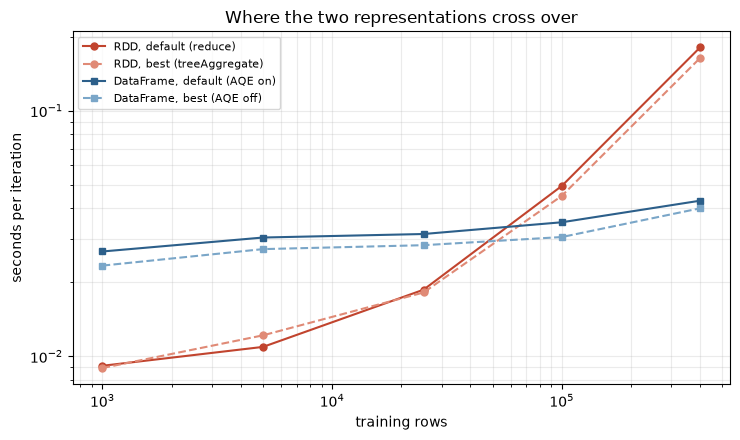

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
styles = {"RDD, default (reduce)": ("o-", "#c1442e"), "RDD, best (treeAggregate)": ("o--", "#e08a76"),
          "DataFrame, default (AQE on)": ("s-", "#2c5f8a"), "DataFrame, best (AQE off)": ("s--", "#7aa6c8")}
for name, (style, colour) in styles.items():
    ax.plot(sw.index, sw[name], style, color=colour, label=name, markersize=5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("training rows"); ax.set_ylabel("seconds per iteration")
ax.set_title("Where the two representations cross over")
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [20]:
def crossover(rdd_col, df_col):
    # The row count at which the two curves meet, by log-log interpolation between
    # the bracketing measurements. An estimate, not a measurement.
    ratio = np.log(sw[rdd_col] / sw[df_col])
    x = np.log(sw.index.to_numpy(dtype=float))
    for i in range(len(x) - 1):
        if ratio.iloc[i] < 0 <= ratio.iloc[i + 1]:
            t = -ratio.iloc[i] / (ratio.iloc[i + 1] - ratio.iloc[i])
            return float(np.exp(x[i] + t * (x[i + 1] - x[i])))
    return float("nan")


print("estimated crossover, rows:")
print(f"  default settings on both sides : {crossover('RDD, default (reduce)', 'DataFrame, default (AQE on)'):,.0f}")
print(f"  best settings on both sides    : {crossover('RDD, best (treeAggregate)', 'DataFrame, best (AQE off)'):,.0f}")
print("\nThe DataFrame's cost grows by a factor of "
      f"{sw['DataFrame, default (AQE on)'].iloc[-1] / sw['DataFrame, default (AQE on)'].iloc[0]:.1f}"
      " across a 400x change in data volume;")
print("the RDD's grows by a factor of "
      f"{sw['RDD, default (reduce)'].iloc[-1] / sw['RDD, default (reduce)'].iloc[0]:.1f}.")

estimated crossover, rows:
  default settings on both sides : 57,836
  best settings on both sides    : 52,445

The DataFrame's cost grows by a factor of 1.6 across a 400x change in data volume;
the RDD's grows by a factor of 19.8.


Three things come out of the sweep, and the first is the one that was asked for.

**The settings do not change the winner at any size.** The RDD is ahead at one, five and
twenty-five thousand rows and behind at one hundred and four hundred thousand, and that is true of
both the default configurations and the best ones. Swapping settings moves each curve by around a
tenth; the curves are an order of magnitude apart at the ends.

**The two APIs have different shapes, and that is what produces the crossover.** On the log-log
plot the RDD lines climb steadily, because their cost is per record. The DataFrame lines are almost
flat until the last point, because their cost is per iteration and does not care how much data the
iteration reads. Two lines of different slope cross exactly once, and where they cross is set by
the ratio of the fixed toll to the per-record work.

**The settings move the crossover, but not out of its neighbourhood.** Removing a job per iteration
is worth proportionally most where fixed cost is everything, so the best settings do pull the
crossing point down — by something like a tenth, on the order of fifty thousand rows either way.
Two cautions about that number. It is an **interpolation** between the two measurements that
bracket it, not a measurement, and it is interpolating between ratios that are themselves noisy, so
it moves by a few thousand rows from one run of this notebook to the next. Read it as "somewhere
around fifty thousand", not as a threshold.

What sets it is the ratio of the DataFrame's fixed per-iteration toll to the RDD's per-record cost,
and neither of those is a setting. That is why the settings move the crossover a little and the
region each API wins in not at all.

**One more thing the sweep corrects.** `treeAggregate` is faster than `reduce` for the RDD at
twenty-five thousand rows and above, and very slightly *slower* below that. Its extra stage is a
fixed cost, so it only pays once there is enough partial merging to pay for it. Section 5c measured
the gain at four hundred thousand rows and read it as a property of the merge; it is a property of
the scale.

The practical reading is that this is a **scale** decision and not a tuning decision. Below roughly
fifty thousand rows the relational version's per-iteration overhead is not yet paid for and the RDD
loop is genuinely quicker; a training set of that size does not need Spark at all, which is worth
saying plainly. Above it the relational version wins by a growing margin, and no combination of the
settings available on either side alters that.

### What the DataFrame's advantage is actually made of

Whole-stage code generation has no RDD equivalent to enable, so it cannot be swapped in either
direction. It can, however, be switched **off**, which is the closest thing available to asking how
much of the relational version's speed comes from compiling the aggregate to JVM bytecode rather
than from avoiding Python.

In [21]:
recache(df_x, StorageLevel.MEMORY_AND_DISK)
attribution = []
for codegen in ("true", "false"):
    spark.conf.set("spark.sql.codegen.wholeStage", codegen)
    lin_gd_df(df_x, n_x)
    attribution.append({"wholeStage codegen": codegen,
                        "DataFrame, s / 10 iterations": round(time_it(lambda: lin_gd_df(df_x, n_x)), 3)})
spark.conf.set("spark.sql.codegen.wholeStage", "true")

att = pd.DataFrame(attribution)
rdd_ref = round(time_it(lambda: lin_gd_rdd(rdd_x, n_x)), 3)
att["RDD, s / 10 iterations"] = rdd_ref
att["DataFrame is x faster"] = (att["RDD, s / 10 iterations"] /
                                att["DataFrame, s / 10 iterations"]).round(2)
print(att.to_string(index=False))
rdd_x.unpersist(); df_x.unpersist()
print("done")

wholeStage codegen  DataFrame, s / 10 iterations  RDD, s / 10 iterations  DataFrame is x faster
              true                         0.433                   1.801                   4.16
             false                         0.551                   1.801                   3.27
done


Turning code generation off slows the relational version down, and it still beats the RDD
comfortably. That places most of the advantage where section 5 said it was: **not in how fast the
arithmetic runs, but in not shipping every row into a Python interpreter to do it.** Code
generation is a second, smaller win layered on top of that one.

---

## 5e. The same thing at ten million rows

Every measurement above stops at four hundred thousand rows, because that is roughly where a
notebook that must finish in a few minutes has to stop. That turns out to be an unfortunate place
to stop: it is far enough past the crossover to show the DataFrame winning, and nowhere near far
enough to show by how much.

The script form of these measurements is

```
code/cloud/08.08 DataFrame vs RDD Benchmark.py
```

with a Dataproc submitter at `code/gcp/run_bench_0808.sh`. It runs the same four loops, makes the
same equality assertions, and performs the same settings swap, but takes the row counts as an
argument so the sweep can go as far as the machine allows. Two things about it differ from this
notebook, both forced by the change of venue.

* **The data is generated on the executors**, by a `flatMap` over partition indices with a
  per-partition seed, rather than built on the driver and shipped out with `sc.parallelize`.
  Sending millions of NumPy arrays out of a driver becomes the dominant cost long before the
  gradient loop does, and it is not the cost under study.
* **It prints rather than plots.** Every output line is prefixed `RESULT` and tab-separated,
  because a serverless batch leaves no notebook and no Spark UI behind and the driver log is the
  entire record of the run.

### What it measured

Run through `spark-submit` on the same four-core laptop, ten iterations, median of two repeats,
576 seconds in total — which is the other reason this is a script and not a cell.

| rows | linear, RDD | linear, DataFrame | × | logistic, RDD | logistic, DataFrame | × |
| ---- | ----------- | ----------------- | - | ------------- | ------------------- | - |
| 25,000 | 0.220 | 0.418 | 0.53 | 0.218 | 0.404 | 0.54 |
| 100,000 | 0.488 | 0.338 | 1.44 | 0.623 | 0.343 | 1.82 |
| 400,000 | 1.728 | 0.303 | 5.71 | 2.051 | 0.334 | 6.15 |
| 2,000,000 | 8.596 | 0.371 | 23.1 | 9.949 | 0.466 | 21.3 |
| 10,000,000 | 42.399 | 0.702 | **60.4** | 48.861 | 1.195 | **40.9** |

Seconds for ten iterations. All ten equality checks passed: the two representations agree on every
parameter at every size.

**Look at the DataFrame columns rather than the ratios.** From twenty-five thousand rows to two
million — eighty times the data — the linear DataFrame loop goes from 0.418 seconds to 0.371, which
is to say it gets slightly *faster*. It is still dominated by the fixed cost of planning the query,
and it has not yet begun to notice the data. Only at ten million does it start to climb.

The RDD columns do the opposite, and do it from the first row. Across the four-hundred-fold
increase the linear RDD loop grows by a factor of 193 and the logistic one by 225 — slightly worse
than linear in the row count, which is what a per-record cost plus a little scheduling looks like.

So the honest summary of the comparison is not the four-times figure this notebook could reach. It
is that **one implementation's cost scales with the data and the other's mostly does not**, and any
single ratio is just a reading of that taken at one dataset size.

### The settings swap at two million rows

| variant | seconds / 10 iterations |
| ------- | ----------------------- |
| RDD, `reduce` | 8.530 |
| RDD, `treeAggregate` | 7.358 |
| DataFrame, adaptive on | 0.326 |
| DataFrame, adaptive off | 0.266 |
| DataFrame, code generation on | 0.302 |
| DataFrame, code generation off | 0.490 |

The conclusions of §5c and §5d survive the change of scale, with one shift worth noting. Code
generation is worth considerably more here than it was at four hundred thousand rows: turning it
off costs about sixty per cent rather than about a quarter, because there is now enough data for
the speed of the compiled loop to matter. Even so, the DataFrame with code generation **disabled**
is still seventeen times faster than the RDD, so the ordering of the two explanations is unchanged.
Most of the advantage remains the absence of a Python round trip.

### On a cluster, at a hundred million rows

**This section was executed on Google Cloud.** Everything above it was measured on a laptop; the
table below was not.

Dataproc Serverless, batch `bench0808-0913-222730`, submitted with

```bash
BENCH_ARGS="--df-only --no-swap" code/gcp/run_bench_0808.sh 1000000,10000000,100000000 10 2
```

| | |
| - | - |
| service | Dataproc Serverless, runtime 3.0, region `us-central1` |
| Spark | 4.0.1 |
| executors | 2 × 4 cores, 16 GB each, dynamic allocation on |
| wall clock | 20 minutes 22 seconds for the whole batch |
| billed | 3,293 DCU-seconds, 240 GB-seconds of shuffle storage |

Only the DataFrame loops were run. The RDD side at a hundred million rows would have dominated the
batch, and the point of going to a cluster was the row count rather than the comparison. `--df-only`
also switches the generator: the DataFrame is built by the engine with `range()` and `rand()`, so no
row crosses into Python. There is therefore no RDD to check agreement against, and instead the
script verifies the generated columns before timing — all three feature means came back at 0.500
and the intercept column at exactly 1.0 at every size.

| rows | partitions | linear, s / iteration | logistic, s / iteration |
| ---- | ---------- | --------------------- | ----------------------- |
| 1,000,000 | 4 | 0.209 | 0.216 |
| 10,000,000 | 40 | 0.704 | 1.212 |
| 100,000,000 | 400 | **5.335** | **11.360** |

### Two things this settles, and one it refutes

**The flat regime ends.** On the laptop the DataFrame loop was still dominated by its fixed
per-iteration cost at two million rows, and barely moved between twenty-five thousand and two
million. It is not flat here. From ten to a hundred million — ten times the data — linear
regression costs 7.6 times more per iteration and logistic 9.4 times more. That is data-bound
behaviour, and it is the regime the whole chapter is about.

**Logistic costs about twice what linear costs, and the gap widens.** At a million rows the two are
indistinguishable, because neither is doing enough arithmetic to matter. At a hundred million the
logistic loop costs 11.4 seconds against the linear loop's 5.3. The exponential and the logarithm
are the difference, and they only become visible once the fixed costs stop dominating. §8.1.4's
argument — that mini-batching pays when the per-example gradient is expensive — has its premise
confirmed here: for logistic regression at scale, per-example arithmetic really is the bill.

**And the refutation.** Before this ran, this notebook predicted that a cluster's larger fixed cost
would matter less than its extra cores, so the DataFrame's per-iteration time would stay roughly
where the laptop had it. It did not. At ten million rows the laptop did an iteration in 0.070
seconds and this eight-core cluster took 0.704 — **ten times slower for the same computation.**

Two things account for it, and neither is a defect.

* **A cluster iteration pays for a network.** Each of these iterations is a job whose tasks are
  scheduled onto remote executors, whose results come back over a wire, and whose driver sits on a
  different machine. On `local[4]` all of that is a function call. The per-iteration floor is
  simply much higher, and ten iterations of a gradient loop is a workload made almost entirely of
  per-iteration costs.
* **The partitioning differs, and that is this notebook's own doing.** The laptop ran ten million
  rows in 4 partitions; the script's rows-per-partition rule gave the cluster 40. Forty tasks on
  eight cores is five waves of scheduling where the laptop had one.

So the honest reading of the cluster run is the one the chapter's cloud appendix already argues for
word count, arrived at independently here: **a distributed system is not a faster computer, it is a
larger one.** The laptop is quicker per iteration and cannot hold a hundred million rows. The
cluster is slower per iteration and does not care how many rows there are. That is the trade, and
it is a capacity trade rather than a speed one.

> **What is still not measured.** The RDD side at a hundred million rows. It was skipped
> deliberately, so the ratios in the table above stop at ten million and no claim is made here
> about how the two representations compare on a cluster. Running it needs only dropping
> `--df-only`, and it will take considerably longer than twenty minutes.

---

## 6. What this does and does not settle

**It settles the performance question, with a caveat about scale.** Which representation is faster
depends on how much data there is, and the crossover on this machine sits somewhere around fifty
thousand rows. Below it the RDD version wins, because the DataFrame version's per-iteration
planning cost is larger than the per-record work it saves. Above it the DataFrame version wins and
keeps pulling away — about four to six times at four hundred thousand rows, and forty to sixty
times at ten million, as §5e measures — because per-record Python serialization grows with the data
and query planning does not. Quoting any single one of those ratios as *the* answer would be a
mistake; the finding is the difference in slope, not a number.

The direction that matters for real work is the second one. A training set that justifies a cluster
is far past the crossover, and there the difference is not marginal. Anyone tempted to read the
chapter's note box as saying that RDDs are the *efficient* choice for this computation should read
the table in section 4 instead.

**It does not overturn the note box's actual argument**, which is about what the code shows a
reader rather than what it costs. Three things are visible in the two implementations above.

* **The RDD version generalizes over the feature count and the DataFrame version does not.** The
  RDD loop infers its parameter count from the data with `len(rdd.first()[1])` and works unchanged
  for any $d$. The DataFrame loop builds one aggregate expression per feature, so the width of the
  query is fixed when the code is written and the plan grows with $d$. At a thousand features that
  is a thousand-column aggregate, re-planned on every iteration.
* **The gradient is legible in one and scattered in the other.** In the RDD version the update rule
  $\sum_i x_i(y_i - \theta^Tx_i)$ appears as one expression over one training example, which is
  what the mathematics says. In the DataFrame version it is assembled from a list comprehension
  over column names, and the per-example structure the chapter spends section 8.1 establishing is
  no longer visible in the code.
* **Anything the relational operators cannot express falls off a cliff.** Both loops here are sums
  of products, which SQL does well. A per-example computation that is not expressible in column
  expressions needs a Python UDF, and a Python UDF reintroduces exactly the serialization cost that
  made the RDD slow — with the DataFrame's constraints still in force.

So the honest summary is a division rather than a winner: **the relational form is the faster way to
run this computation, and the RDD form is the clearer way to explain it.** In practice neither is
what a production job should use, because `LinearRegression` and `LogisticRegression` already do
this with a better optimizer, standardization, and an aggregation strategy tuned for the case where
$d$ is large.